# Homework Review: Dirichlet Priors, Polynomial Regressors, Bernoulli Bayes Classifier

**EECE5644 Recitation 8 · Homework review**

Each part below gives the **question**, then the **answer**, then (where it helps) a short **code demo**. The parts that are a short derivation have no code.

| Problem | Topic | Code |
|---|---|---|
| Question 4 | Dirichlet prior; ML vs MAP vs posterior mean | 4.4 only |
| Problem 5 | Optimal and polynomial MMSE regressors | (a) numerical check, (c) plots |
| Problem 8 | Bernoulli Bayes classifier, linear discriminant | (b) table and boundary plot |
| HW4 Problem 3 (student question) | Ridge regression: assignment's $\lambda$ vs textbook's $\kappa$ | none |

**Run from top to bottom.** No data files needed. Dependencies: `pip install numpy pandas scipy matplotlib jupyterlab`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from scipy.integrate import quad

plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': 0.18})
BLUE, ORANGE, GREEN, GRAY = '#2768a6', '#d66b2b', '#278267', '#8a8a8a'
SEED = 42

---
# Question 4 (20%)

> Consider a categorical random variable $X$ with $K$ possible categories, i.e., $X\in\{1,\dots,K\}$. For example, in the case of dice rolls, we have $K=6$ categories, each corresponding to possible outcomes. Denote by
> $$\theta_k=P(X=k)$$
> the probability that we observe outcome $k$. Suppose that we collect a dataset $\mathcal D=\{x_1,x_2,\dots,x_N\}$ of i.i.d. samples from this distribution.

## 4.1

> Show that
> $$p(\mathcal D\mid\theta)=\prod_{k=1}^K\theta_k^{N_k},$$
> where $N_k=\sum_{i=1}^N\mathbb 1_{x_i=k}$ is the number of times outcome $k$ occurs in $\mathcal D$.

### Answer

By independence, $p(\mathcal D\mid\theta)=\prod_{i=1}^N P(x_i\mid\theta)=\prod_{i=1}^N\theta_{x_i}$.

Group the factors by category: $\theta_k$ appears once for every sample equal to $k$, i.e. $N_k$ times. Hence

$$p(\mathcal D\mid\theta)=\prod_{k=1}^K\theta_k^{N_k}.$$

*Example (a die).* $\mathcal D=\{3,1,3,6\}$ gives $N=(1,0,2,0,0,1)$ and $p(\mathcal D\mid\theta)=\theta_1\,\theta_3^2\,\theta_6$. The order of the rolls does not matter; only the counts $N_k$ do (they are a *sufficient statistic*).

## 4.2

> Consider the Dirichlet prior distribution
> $$p(\theta)\propto\prod_{k=1}^K\theta_k^{\alpha_k-1},$$
> where $\alpha_k\ge1$, for $k=1,\dots,K$, are called hyperparameters.¹ Show that, under this prior, the posterior is also Dirichlet, i.e.,
> $$p(\theta\mid\mathcal D)\propto\prod_{k=1}^K\theta_k^{\alpha'_k-1}$$
> for appropriately defined $\alpha'_k\ge1$, $k=1,\dots,K$, and find these values.
>
> ¹ *To get the full distribution, one would need to multiply the r.h.s. by a constant so that $\int_{\theta\in S}p(\theta)\,d\theta=1$, where $S=\{\theta\ge0:\sum_k\theta_k=1\}$ is the set of valid parameters (the $K$-dimensional simplex).*

### Answer

Bayes' rule, then add exponents:

$$p(\theta\mid\mathcal D)\ \propto\ p(\mathcal D\mid\theta)\,p(\theta)=\prod_k\theta_k^{N_k}\prod_k\theta_k^{\alpha_k-1}=\prod_k\theta_k^{N_k+\alpha_k-1}
\quad\Longrightarrow\quad \boxed{\alpha'_k=N_k+\alpha_k}$$

Since $N_k\ge0$ and $\alpha_k\ge1$, also $\alpha'_k\ge1$. (Slide 44.)

**Intuition: $\alpha_k$ are pseudo-counts.** The prior acts like $\alpha_k-1$ imaginary observations of category $k$ made before the data; the posterior just adds the real counts. (The normalising constant from the footnote is $\prod_k\Gamma(\alpha_k)/\Gamma(\alpha_0)$ with $\alpha_0=\sum_k\alpha_k$; we never need it to find $\alpha'_k$.)

*Example.* $K=3$, prior $\alpha=(1,1,1)$, data counts $N=(12,6,2)$ $\Rightarrow$ posterior $\alpha'=(13,7,3)$.

## 4.3

> Show that if $\alpha_1=\alpha_2=\dots=\alpha_K=1$, then the prior becomes the uniform distribution over valid $\theta$ (i.e., this is an "uninformative prior").

### Answer

$$p(\theta)\propto\prod_k\theta_k^{1-1}=\prod_k\theta_k^{0}=1,$$

a constant over the simplex of valid $\theta$, so the prior is uniform.

## 4.4

> In class we discussed the following three estimators of $\theta_k$, $k=1,\dots,K$, each corresponding to ML, MAP, and the mean of full Bayesian estimation:
> $$\hat\theta_k^{\text{ML}}=\frac{N_k}{N},\qquad\hat\theta_k^{\text{MAP}}=\frac{N_k+\alpha_k-1}{N+\alpha_0-K},\qquad\bar\theta_k=\mathbb E[\theta_k\mid\mathcal D]=\frac{N_k+\alpha_k}{N+\alpha_0},$$
> where $\alpha_0=\sum_k\alpha_k$. Suppose, as in Q3, that $\mathcal D=\{x_1\}$, i.e., we have only collected one sample. What would each of these estimates look like for each $k=1,\dots,K$ under an uninformative prior? Which of these makes most sense, and why?

### Answer

**First, how to read the formulas: pseudo-counts.** Since $\alpha_0-K=\sum_k(\alpha_k-1)$, the MAP formula can be rewritten as

$$\hat\theta_k^{\text{MAP}}=\frac{N_k+(\alpha_k-1)}{N+\sum_{k'}(\alpha_{k'}-1)}=\frac{\text{real count of }k\;+\;\text{pseudo-count of }k}{\text{total real count}\;+\;\text{total pseudo-count}} .$$

So $\alpha_k-1$ is the number of **imaginary observations** of category $k$ that the prior adds before we look at the data (the same pseudo-counts as in 4.2). All three estimators are "count, then divide by the total"; they differ only in how many pseudo-counts they add to each category:

| Estimator | Pseudo-count added to each category | With $\alpha_k=1$ |
|---|---|---|
| ML | $0$ | $\dfrac{N_k}{N}$ |
| MAP | $\alpha_k-1$ | $\dfrac{N_k+0}{N+0}=\dfrac{N_k}{N}$ (same as ML) |
| Posterior mean | $\alpha_k$ | $\dfrac{N_k+1}{N+K}$ |

With the uninformative prior $\alpha_k=1$, the MAP adds $\alpha_k-1=0$ pseudo-counts, which is why it is identical to ML. The posterior mean adds one more, so it is "add one to every count".

**Now plug in one sample.** $x_1=j$ and $\alpha_k=1$ (so $\alpha_0=K$): $N=1$, $N_j=1$, all other $N_k=0$.

$$\hat\theta_k^{\text{ML}}=\hat\theta_k^{\text{MAP}}=\begin{cases}1&k=j\\0&k\ne j\end{cases}
\qquad\qquad
\mathbb E[\theta_k\mid\mathcal D]=\begin{cases}\dfrac{2}{K+1}&k=j\\[2mm]\dfrac{1}{K+1}&k\ne j\end{cases}$$

(Check: $\tfrac{2}{K+1}+\tfrac{K-1}{K+1}=1$.)

**The posterior mean makes most sense.** After a single roll, ML and MAP declare every unseen category **impossible**. The posterior mean still favours $j$, but keeps every outcome possible and sums to 1. This is the discrete counterpart of getting $\hat\sigma^2=0$ from a single Gaussian sample.

Two remarks:

- **MAP = ML here because the prior is flat:** the mode of likelihood × constant is the mode of the likelihood. In pseudo-count terms: $\alpha_k-1=0$, so the prior adds nothing.
- **The posterior mean blends ML with the prior mean:**
$$\mathbb E[\theta_k\mid\mathcal D]=\frac{N}{N+\alpha_0}\cdot\frac{N_k}{N}+\frac{\alpha_0}{N+\alpha_0}\cdot\frac{\alpha_k}{\alpha_0},$$
so $\alpha_0$ acts as the prior's "sample size": it matters with few data, and fades as $N$ grows.

### Demo 1: the three estimates after one roll of a die

In [2]:
def estimators(counts, alpha):
    counts, alpha = np.asarray(counts, float), np.asarray(alpha, float)
    N, K, a0 = counts.sum(), len(counts), alpha.sum()
    return pd.DataFrame({'ML': counts / N,
                         'MAP': (counts + alpha - 1) / (N + a0 - K),
                         'Posterior mean': (counts + alpha) / (N + a0)},
                        index=[f'face {k + 1}' for k in range(K)])

# One roll of a six-sided die came up 3.
one_roll = np.bincount([2], minlength=6)
print('Uniform prior, alpha = 1:')
display(estimators(one_roll, np.ones(6)).round(3))
print('Prior alpha = 2 (one pseudo-count per face): now MAP is "add-one" smoothing too')
display(estimators(one_roll, 2 * np.ones(6)).round(3))

Uniform prior, alpha = 1:


,ML,MAP,Posterior mean
face 1,0.0,0.0,0.143
face 2,0.0,0.0,0.143
face 3,1.0,1.0,0.286
face 4,0.0,0.0,0.143
face 5,0.0,0.0,0.143
face 6,0.0,0.0,0.143


Prior alpha = 2 (one pseudo-count per face): now MAP is "add-one" smoothing too


,ML,MAP,Posterior mean
face 1,0.0,0.143,0.154
face 2,0.0,0.143,0.154
face 3,1.0,0.286,0.231
face 4,0.0,0.143,0.154
face 5,0.0,0.143,0.154
face 6,0.0,0.143,0.154


**First table ($\alpha=1$, the homework case).** ML and MAP are identical (1 for face 3, 0 elsewhere), because MAP adds $\alpha_k-1=0$ pseudo-counts. The posterior mean adds one pseudo-count per face: counts $(0,0,1,0,0,0)$ become $(1,1,2,1,1,1)$, total 7, giving $2/7\approx0.286$ and $1/7\approx0.143$.

**Second table ($\alpha=2$, not asked in the homework). What it shows:** the zeros are **not** a flaw of MAP itself; they come from the prior adding no pseudo-counts. With $\alpha_k=2$, MAP adds $\alpha_k-1=1$ pseudo-count per face, so it no longer gives zeros, and it equals $(N_k+1)/(N+K)$, the same "add-one" answer as the $\alpha=1$ posterior mean. (The posterior mean now adds $\alpha_k=2$ per face: $(N_k+2)/(N+2K)$, i.e. $3/13\approx0.231$ and $2/13\approx0.154$.)

### Demo 2: does it matter beyond $N=1$?

A loaded die with true $\theta=(0.30,0.25,0.20,0.15,0.07,0.03)$. For each $N$ we repeat the experiment 5,000 times. **Left:** how often ML assigns probability 0 to a face that can occur (any future roll of it would get log loss $=\infty$). **Right:** the mean squared error $\sum_k(\hat\theta_k-\theta_k)^2$.

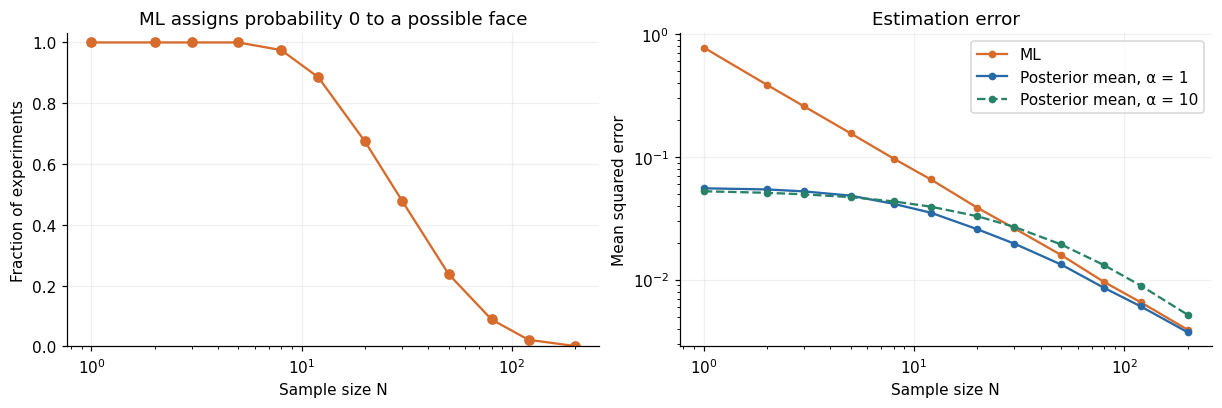

In [3]:
theta_die = np.array([0.30, 0.25, 0.20, 0.15, 0.07, 0.03])
Ns = np.array([1, 2, 3, 5, 8, 12, 20, 30, 50, 80, 120, 200])
n_rep = 5000
rng = np.random.default_rng(SEED)

zero_frac, sq_err = [], {'ML': [], 'Posterior mean, α = 1': [], 'Posterior mean, α = 10': []}
for N in Ns:
    counts = rng.multinomial(N, theta_die, size=n_rep)            # (n_rep, 6)
    ml = counts / N
    zero_frac.append(np.mean((ml == 0).any(axis=1)))
    for name, est in [('ML', ml),
                      ('Posterior mean, α = 1', (counts + 1) / (N + 6)),
                      ('Posterior mean, α = 10', (counts + 10) / (N + 60))]:
        sq_err[name].append(np.mean(((est - theta_die) ** 2).sum(axis=1)))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), constrained_layout=True)
axes[0].plot(Ns, zero_frac, 'o-', color=ORANGE)
axes[0].set(xscale='log', xlabel='Sample size N', ylim=(0, 1.03),
            ylabel='Fraction of experiments', title='ML assigns probability 0 to a possible face')
for (name, err), col, ls in zip(sq_err.items(), [ORANGE, BLUE, GREEN], ['-', '-', '--']):
    axes[1].plot(Ns, err, 'o', ls=ls, color=col, label=name, ms=4)
axes[1].set(xscale='log', yscale='log', xlabel='Sample size N', ylabel='Mean squared error',
            title='Estimation error')
axes[1].legend()
plt.show()

**What to notice.**

- **Left:** up to about $N\approx30$, ML misses the rare face (true probability 0.03) in most experiments. The posterior mean never assigns 0.
- **Right:** for small $N$ the posterior mean with $\alpha=1$ beats ML by an order of magnitude; for large $N$ they merge. The strong prior $\alpha=10$ (60 pseudo-counts pulling toward a *fair* die) is no better at tiny $N$ and the worst from $N\approx10$ on, because this die is not fair. The prior is a bet; a mild one is the safe default.

---
# Problem 5: Regressors for the Homoskedastic Model (10 pts)

> *Topic: Nonlinear and polynomial regressors and their performances.* Consider the additive noise homoskedastic model
> $$x\sim U(0,1),\qquad f(x)=0.5+x+3x^2+\sin(2\pi x),\qquad y=f(x)+\epsilon,\quad \epsilon\sim\mathcal N(0,\sigma^2),\quad \epsilon\perp x$$
> and the corresponding parametric regressor
> $$h(x;\mathbf w)=w_0+w_1x+\dots+w_Mx^M=w_0+\mathbf w^T\mathbf x,$$
> where $\mathbf w=(w_1,\dots,w_M)$ and $\mathbf x=(x,x^2,\dots,x^M)$.

*Homoskedastic* means the noise variance $\sigma^2$ is the same for every value of $x$.

## 5(a)

> Show that the mean and variance of the output variable $y$ are given by $\mu_y=2$ and $\sigma_y^2=(113/60)-(\pi/4)+\sigma^2$, respectively.

### Answer

**Mean.** Since $\mathbb E[\epsilon]=0$ and $\int_0^1\sin(2\pi x)\,dx=0$,

$$\mu_y=\mathbb E[f(x)]=\int_0^1\Big(\tfrac12+x+3x^2+\sin(2\pi x)\Big)dx=\tfrac12+\tfrac12+1+0=\boxed{2}.$$

**Variance.** Because $\epsilon\perp x$, $\ \sigma_y^2=\operatorname{Var}f(x)+\sigma^2$, and $\operatorname{Var}f(x)=\mathbb E[f(x)^2]-\mu_y^2$. Write $f=g+s$ with $g(x)=\tfrac12+x+3x^2$ and $s(x)=\sin(2\pi x)$. Then $\mathbb E[f^2]=\int g^2+\int s^2+2\int g\,s$:

| Term | Value |
|---|---|
| $\int_0^1 g^2\,dx=\int_0^1\big(9x^4+6x^3+4x^2+x+\tfrac14\big)dx$ | $\tfrac95+\tfrac32+\tfrac43+\tfrac12+\tfrac14=\tfrac{323}{60}$ |
| $\int_0^1\sin^2(2\pi x)\,dx$ | $\tfrac12$ |
| $\int_0^1 g(x)\sin(2\pi x)\,dx$ (use $\int_0^1x\sin(2\pi x)dx=\int_0^1x^2\sin(2\pi x)dx=-\tfrac1{2\pi}$) | $-\tfrac1{2\pi}-\tfrac3{2\pi}=-\tfrac2\pi$ |

$$\mathbb E[f^2]=\tfrac{323}{60}+\tfrac12-\tfrac4\pi=\tfrac{353}{60}-\tfrac4\pi,\qquad
\operatorname{Var}f=\tfrac{353}{60}-\tfrac4\pi-4=\tfrac{113}{60}-\tfrac4\pi,\qquad
\boxed{\sigma_y^2=\tfrac{113}{60}-\tfrac4\pi+\sigma^2}.$$

> **Note: typo in the problem statement.** It prints $\pi/4$; the correct term is $4/\pi$. The quick numerical check below confirms this.

In [4]:
def f(x):
    return 0.5 + x + 3 * x**2 + np.sin(2 * np.pi * x)

sigma2 = 0.1
mu_y = quad(f, 0, 1)[0]
var_f = quad(lambda x: f(x)**2, 0, 1)[0] - mu_y**2
print(f'mu_y               = {mu_y:.6f}')
print(f'Var f(x) (numeric) = {var_f:.6f}')
print(f'113/60 - 4/pi      = {113/60 - 4/np.pi:.6f}   <- matches')
print(f'113/60 - pi/4      = {113/60 - np.pi/4:.6f}   <- value printed in the problem (typo)')

rng = np.random.default_rng(SEED)
x_mc = rng.uniform(0, 1, 1_000_000)
y_mc = f(x_mc) + rng.normal(0, np.sqrt(sigma2), x_mc.size)
print(f'\nSimulation, 10^6 samples, sigma^2 = 0.1: mean {y_mc.mean():.4f}, variance {y_mc.var():.4f} '
      f'(formula: {113/60 - 4/np.pi + sigma2:.4f})')

mu_y               = 2.000000
Var f(x) (numeric) = 0.610094
113/60 - 4/pi      = 0.610094   <- matches
113/60 - pi/4      = 1.097935   <- value printed in the problem (typo)

Simulation, 10^6 samples, sigma^2 = 0.1: mean 2.0008, variance 0.7095 (formula: 0.7101)


## 5(b)

> For vector $\mathbf x$, show that the mean vector $\boldsymbol\mu_x$, the covariance matrix $\Sigma_{xx}$, and the cross-covariance vector $\boldsymbol\sigma_{xy}$ are given by
> $$\boldsymbol\mu_x=\mathbb E\{[x\ x^2\ \cdots\ x^M]^T\}=\big[\tfrac12\ \tfrac13\ \cdots\ \tfrac1{M+1}\big]^T,\qquad
\Sigma_{xx}=\mathbb E\{\mathbf x\mathbf x^T\}-\boldsymbol\mu_x\boldsymbol\mu_x^T=\Big[\frac{ij}{(i+1)(j+1)(i+j+1)}\Big]_{i,j=1}^M,$$
> $$\boldsymbol\sigma_{xy}=\mathbb E\big[x f(x)\ \ x^2f(x)\ \cdots\ x^Mf(x)\big]^T-\boldsymbol\mu_x\mu_y .$$

### Answer

Everything follows from one fact: for $x\sim U(0,1)$, $\ \mathbb E[x^i]=\int_0^1x^i\,dx=\dfrac1{i+1}$.

- **Mean:** entry $i$ of $\mathbf x$ is $x^i$, so $[\boldsymbol\mu_x]_i=\dfrac1{i+1}$.
- **Covariance:** $[\Sigma_{xx}]_{ij}=\mathbb E[x^ix^j]-\mathbb E[x^i]\mathbb E[x^j]=\dfrac1{i+j+1}-\dfrac1{(i+1)(j+1)}=\dfrac{(i+1)(j+1)-(i+j+1)}{(i+1)(j+1)(i+j+1)}=\dfrac{ij}{(i+1)(j+1)(i+j+1)}$.
- **Cross-covariance:** $\operatorname{Cov}(x^i,y)=\mathbb E[x^iy]-\mathbb E[x^i]\mu_y$, and $\mathbb E[x^iy]=\mathbb E[x^if(x)]+\mathbb E[x^i]\,\mathbb E[\epsilon]=\mathbb E[x^if(x)]$ since $\epsilon\perp x$ with zero mean. The entries are
$$\mathbb E[x^if(x)]=\frac1{2(i+1)}+\frac1{i+2}+\frac3{i+3}+\int_0^1x^i\sin(2\pi x)\,dx .$$

**What these are for.** $h$ is a polynomial in $x$ but **linear in the feature vector** $\mathbf x$, so the linear MMSE formulas apply directly:

$$\boxed{\mathbf w=\Sigma_{xx}^{-1}\boldsymbol\sigma_{xy},\qquad w_0=\mu_y-\mathbf w^T\boldsymbol\mu_x}.$$

## 5(c)

> Using $\sigma^2=0.1$, obtain two plots for the optimum nonlinear regressor and linear regressors of order $M=2,3$, and $5$, as shown in Slide 26 of the lecture notes "Optimal Prediction and Learning".

### Answer

Both regressors answer the same question: **which $h$ minimises the risk $R(h)=\mathbb E\big[(y-h(x))^2\big]$?** They differ in which functions $h$ are allowed.

#### Step 1. The risk of any regressor $h$

Substitute $y=f(x)+\epsilon$ and expand the square:

$$R(h)=\mathbb E\big[(f(x)-h(x)+\epsilon)^2\big]=\mathbb E\big[(f(x)-h(x))^2\big]+2\,\mathbb E\big[(f(x)-h(x))\,\epsilon\big]+\mathbb E[\epsilon^2].$$

- The cross term is 0: $\epsilon$ is independent of $x$, so $\mathbb E[(f(x)-h(x))\epsilon]=\mathbb E[f(x)-h(x)]\cdot\mathbb E[\epsilon]=0$.
- $\mathbb E[\epsilon^2]=\sigma^2$.
- $x\sim U(0,1)$ has density 1 on $[0,1]$, so the first expectation is an integral.

$$\boxed{R(h)=\sigma^2+\int_0^1\big(f(x)-h(x)\big)^2\,dx}$$

**Risk = irreducible noise + how far $h$ is from $f$.** The first term is the same for every $h$; only the second depends on our choice.

#### Step 2. Optimal nonlinear regressor (any function allowed)

The integral is $\ge0$ and equals 0 exactly when $h=f$. So

$$h_o(x)=f(x)=\mathbb E[y\mid x],\qquad R_o=\sigma^2=0.1 .$$

No regressor can do better than $\sigma^2$: the noise $\epsilon$ is unpredictable.

#### Step 3. Polynomial regressor of order $M$ (why the linear MMSE formula applies)

Now $h$ must be a polynomial, $h(x)=w_0+\mathbf w^T\mathbf x$ with $\mathbf x=(x,x^2,\dots,x^M)$. It is nonlinear in $x$, but **linear in the parameters $(w_0,\mathbf w)$ and in the feature vector $\mathbf x$**. Treat $\mathbf x$ as an $M$-dimensional input; the problem becomes "the best **linear** predictor of $y$ from $\mathbf x$", which is exactly the linear MMSE problem. Its solution:

1. **Intercept.** Set $\partial R/\partial w_0=-2\,\mathbb E[y-w_0-\mathbf w^T\mathbf x]=0$, which gives $w_0=\mu_y-\mathbf w^T\boldsymbol\mu_x$.
2. **Slopes.** Put $w_0$ back in, so $R=\mathbb E\big[\big((y-\mu_y)-\mathbf w^T(\mathbf x-\boldsymbol\mu_x)\big)^2\big]=\sigma_y^2-2\mathbf w^T\boldsymbol\sigma_{xy}+\mathbf w^T\Sigma_{xx}\mathbf w$. Set the gradient to zero: $-2\boldsymbol\sigma_{xy}+2\Sigma_{xx}\mathbf w=0$.

$$\boxed{\mathbf w=\Sigma_{xx}^{-1}\boldsymbol\sigma_{xy},\qquad w_0=\mu_y-\mathbf w^T\boldsymbol\mu_x}$$

This is why 5(b) asked for $\boldsymbol\mu_x$, $\Sigma_{xx}$ and $\boldsymbol\sigma_{xy}$: they are the only ingredients. They are **population** moments (integrals), so no data are needed and the answer is exact.

The minimum risk can be read off in two equivalent ways (both give e.g. $R_2=0.2960$):

$$R_M=\sigma^2+\int_0^1\big(f(x)-h_M(x)\big)^2dx\qquad\text{or}\qquad R_M=\sigma_y^2-\boldsymbol\sigma_{xy}^T\Sigma_{xx}^{-1}\boldsymbol\sigma_{xy}.$$

The second form says: the polynomial explains $\boldsymbol\sigma_{xy}^T\Sigma_{xx}^{-1}\boldsymbol\sigma_{xy}$ of the total variance $\sigma_y^2$; the rest is the risk.

#### Role of $\sigma^2$

$\sigma^2$ does **not** change any regression curve: $\boldsymbol\sigma_{xy}$ only involves $f$ ($\epsilon$ contributes $\mathbb E[x^i\epsilon]=0$), so $\mathbf w$ does not depend on $\sigma^2$. It only shifts every risk up by the same amount. (The problem's "$\sigma^2=01$" means $0.1$.)

The code below is a direct transcription of Step 3 with the 5(b) formulas, and of the Step 1 risk.

,w0,w1,w2,w3,w4,w5,Risk R_M
M,,,,,,,
2,1.454930,-0.909859,3.000000,,,,0.296036
3,0.296688,12.989044,-31.747257,23.164838,,,0.104390
5,0.515977,6.410357,14.303548,-99.637308,138.152415,-55.260966,0.100018


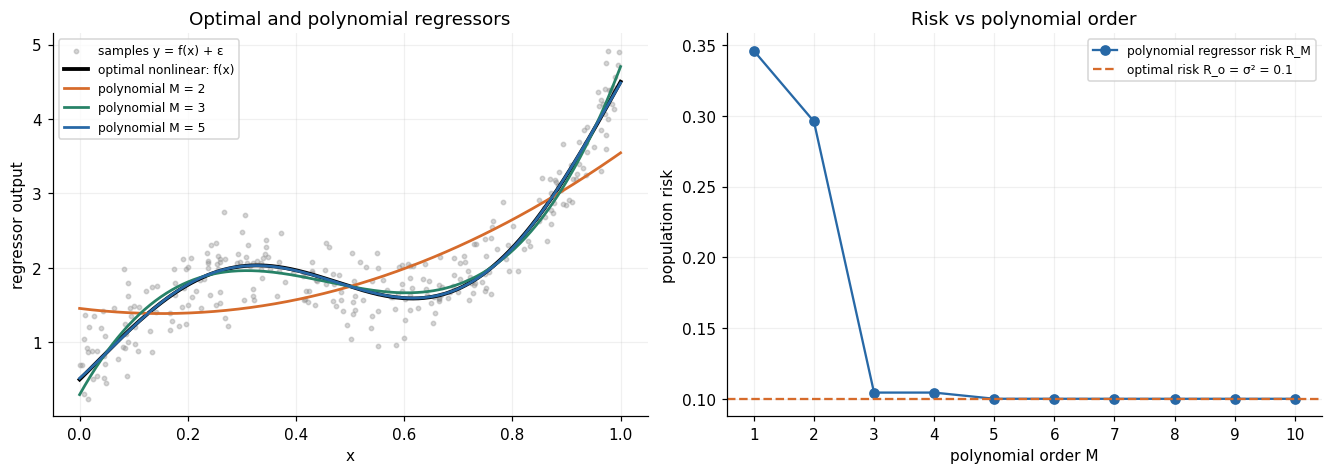

In [5]:
def poly_mmse(M):
    # Linear MMSE coefficients (w0, w1, ..., wM) from the population moments of 5(b).
    i = np.arange(1, M + 1)
    mu_x = 1 / (i + 1)                                                    # (4a)
    S_xx = 1 / (i[:, None] + i[None, :] + 1) - np.outer(mu_x, mu_x)       # (4b)
    E_xf = np.array([quad(lambda x, p=p: x**p * f(x), 0, 1)[0] for p in i])
    s_xy = E_xf - mu_x * mu_y                                             # (4c)
    w = np.linalg.solve(S_xx, s_xy)
    return np.r_[mu_y - w @ mu_x, w]

def h(coef, x):
    return np.polynomial.polynomial.polyval(x, coef)                      # w0 + w1 x + ... + wM x^M

def risk(coef):
    return sigma2 + quad(lambda x: (f(x) - h(coef, x))**2, 0, 1, limit=200)[0]

coefs = {M: poly_mmse(M) for M in range(1, 11)}
coef_table = pd.DataFrame([dict({f'w{k}': c for k, c in enumerate(coefs[M])}, **{'Risk R_M': risk(coefs[M])})
                           for M in (2, 3, 5)], index=pd.Index([2, 3, 5], name='M'))
coef_table = coef_table[[f'w{k}' for k in range(6)] + ['Risk R_M']]
display(coef_table.round(6).fillna(''))

xs = np.linspace(0, 1, 400)
x_s = rng.uniform(0, 1, 300)
y_s = f(x_s) + rng.normal(0, np.sqrt(sigma2), x_s.size)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), constrained_layout=True)
ax = axes[0]
ax.scatter(x_s, y_s, s=8, color=GRAY, alpha=0.35, label='samples y = f(x) + ε')
ax.plot(xs, f(xs), color='k', lw=2.5, label='optimal nonlinear: f(x)')
for M, col in [(2, ORANGE), (3, GREEN), (5, BLUE)]:
    ax.plot(xs, h(coefs[M], xs), color=col, lw=1.8, label=f'polynomial M = {M}')
ax.set(xlabel='x', ylabel='regressor output', title='Optimal and polynomial regressors')
ax.legend(fontsize=8)

ax = axes[1]
Ms = list(coefs)
ax.plot(Ms, [risk(coefs[M]) for M in Ms], 'o-', color=BLUE, label='polynomial regressor risk R_M')
ax.axhline(sigma2, color=ORANGE, ls='--', label='optimal risk R_o = σ² = 0.1')
ax.set(xlabel='polynomial order M', ylabel='population risk', xticks=Ms,
       title='Risk vs polynomial order')
ax.legend(fontsize=8)
plt.show()

**What to notice.**

- **$M=2$** captures the quadratic part $0.5+x+3x^2$ exactly (note $w_2=3$) but cannot bend for the sine wave, so $R_2\approx0.296$.
- **$M=3$** already follows the wiggle: $R_3\approx0.104$, close to the floor $0.1$. **$M=5$** is visually on top of $f$: $R_5\approx0.10002$.
- The risk **never increases** with $M$: the models are nested (an order-$(M+1)$ polynomial can set $w_{M+1}=0$). It approaches, but never goes below, the irreducible noise $\sigma^2=0.1$.
- $R_4=R_3$ and $R_6=R_5$: what is left to fit after the quadratic part is $\sin(2\pi x)$, which is antisymmetric about $x=\tfrac12$, so adding an even power does not help.

---
# Problem 8: Binary Classification of Categorical Input (10 pts)

> *Topic: Discriminant function, decision boundary, and classification.* A survey of regular customers of two restaurants, MickeyD's ($\mathcal C_1$) and BKing ($\mathcal C_2$), asked whether each customer likes cheeseburgers and whether they like french fries. Each customer is described by a binary feature vector $\mathbf x=(x_1,x_2)$, where $x_1=1$ if the customer likes cheeseburgers (0 otherwise) and $x_2=1$ if the customer likes french fries (0 otherwise). The survey produced the following class-conditional probabilities $p_{k,i}=P(x_i=1\mid\mathcal C_k)$:
>
> | | Likes cheeseburger ($i=1$) | Likes french fries ($i=2$) |
> |---|---|---|
> | MickeyD's customers ($k=1$) | $p_{1,1}=0.7$ | $p_{1,2}=0.2$ |
> | BKing customers ($k=2$) | $p_{2,1}=0.6$ | $p_{2,2}=0.6$ |
>
> Note that the rows are not probability distributions and need not sum to 1.
>
> Assume the features are conditionally independent Bernoulli random variables given the class, so that
> $$p(\mathbf x\mid\mathcal C_k)=\prod_{i=1}^Dp_{k,i}^{x_i}(1-p_{k,i})^{1-x_i},\qquad k=1,2,\quad x_i\in\{0,1\},\quad D=2. \tag{5}$$
> Assume that the prior probabilities are $P(\mathcal C_1)=0.7$ and $P(\mathcal C_2)=0.3$. Define the discriminant function as the log posterior ratio
> $$g(\mathbf x)=\log\frac{P(\mathcal C_1\mid\mathbf x)}{P(\mathcal C_2\mid\mathbf x)} \tag{6}$$
> and assign $\mathbf x$ to $\mathcal C_1$ if $g(\mathbf x)>0$ and to $\mathcal C_2$ if $g(\mathbf x)<0$.

**Why the rows need not sum to 1.** $p_{1,1}=0.7$ and $p_{1,2}=0.2$ answer two *separate* yes/no questions (each is one Bernoulli parameter), not the probabilities of two competing outcomes.

## 8(a)

> Show that $g(\mathbf x)$ is a linear function of $\mathbf x$,
> $$g(\mathbf x)=\sum_{i=1}^Dw_ix_i+w_0, \tag{7}$$
> where
> $$w_i=\log\Big[\frac{p_{1,i}(1-p_{2,i})}{p_{2,i}(1-p_{1,i})}\Big],\quad i=1,\dots,D,\qquad w_0=\sum_{i=1}^D\log\Big[\frac{1-p_{1,i}}{1-p_{2,i}}\Big]+\log\Big[\frac{P(\mathcal C_1)}{P(\mathcal C_2)}\Big]. \tag{8}$$
> Compute the numerical values of $w_1$, $w_2$, and $w_0$.

### Answer

Start from the definition (6) and apply Bayes' rule ($p(\mathbf x)$ cancels in the ratio):

$$g(\mathbf x)=\log\frac{P(\mathcal C_1\mid\mathbf x)}{P(\mathcal C_2\mid\mathbf x)}=\log\frac{p(\mathbf x\mid\mathcal C_1)}{p(\mathbf x\mid\mathcal C_2)}+\log\frac{P(\mathcal C_1)}{P(\mathcal C_2)} .$$

Taking the log of the Bernoulli product turns it into a sum, and $x_i$ moves out of the exponent:

$$\log p(\mathbf x\mid\mathcal C_k)=\sum_{i=1}^D\Big[x_i\log p_{k,i}+(1-x_i)\log(1-p_{k,i})\Big].$$

Subtract the two classes and collect the terms with and without $x_i$:

$$g(\mathbf x)=\sum_i\Big[x_i\log\frac{p_{1,i}}{p_{2,i}}+(1-x_i)\log\frac{1-p_{1,i}}{1-p_{2,i}}\Big]+\log\frac{P(\mathcal C_1)}{P(\mathcal C_2)}
=\sum_i x_i\underbrace{\log\frac{p_{1,i}(1-p_{2,i})}{p_{2,i}(1-p_{1,i})}}_{w_i}+\underbrace{\sum_i\log\frac{1-p_{1,i}}{1-p_{2,i}}+\log\frac{P(\mathcal C_1)}{P(\mathcal C_2)}}_{w_0}.$$

**Numerically:**

$$w_1=\log\frac{0.7\times0.4}{0.6\times0.3}=\log\frac{14}{9}=0.4418,\qquad
w_2=\log\frac{0.2\times0.4}{0.6\times0.8}=\log\frac16=-1.7918,$$
$$w_0=\log\frac{0.3}{0.4}+\log\frac{0.8}{0.4}+\log\frac{0.7}{0.3}=\log\frac72=1.2528 .$$

**Reading the weights.** $w_1>0$: liking cheeseburgers is mild evidence for MickeyD's ($0.7$ vs $0.6$). $w_2<0$ and large: liking fries is strong evidence for BKing ($0.6$ vs $0.2$).

## 8(b)

> Plot the decision boundary $g(\mathbf x)=0$ as a line in the $(x_1,x_2)$ plane. Mark the four possible input vectors $(0,0)$, $(0,1)$, $(1,0)$, and $(1,1)$, and label each with its assigned class.

### Answer

The boundary is $g(\mathbf x)=0$: $\ 0.4418\,x_1-1.7918\,x_2+1.2528=0$, i.e. $x_2\approx0.2466\,x_1+0.6992$. The input can only take the **four** corner values $(0,0),(0,1),(1,0),(1,1)$.

The code computes $g$ in two ways for each input, from the linear formula of 8(a) and directly from Bayes' rule, to check they agree, and then draws the boundary.

w1 = 0.4418, w2 = -1.7918, w0 = 1.2528


,p(x|C1),p(x|C2),g from Bayes rule,g = w·x + w0,decision
x,,,,,
"(0, 0)",0.24,0.16,1.2528,1.2528,C1 (MickeyD's)
"(0, 1)",0.06,0.24,-0.5390,-0.5390,C2 (BKing)
"(1, 0)",0.56,0.24,1.6946,1.6946,C1 (MickeyD's)
"(1, 1)",0.14,0.36,-0.0972,-0.0972,C2 (BKing)


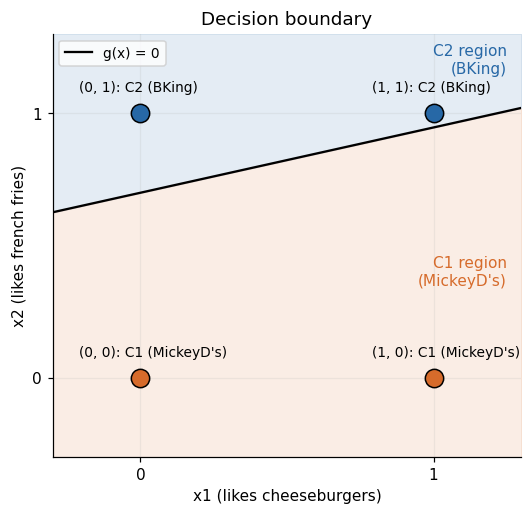

In [6]:
p = np.array([[0.7, 0.2],      # MickeyD's: P(like cheeseburger), P(like fries)
              [0.6, 0.6]])     # BKing
prior = np.array([0.7, 0.3])   # P(C1), P(C2)

w = np.log(p[0] * (1 - p[1]) / (p[1] * (1 - p[0])))                       # w_i, eq. (7)
w0 = np.sum(np.log((1 - p[0]) / (1 - p[1]))) + np.log(prior[0] / prior[1])
print(f'w1 = {w[0]:.4f}, w2 = {w[1]:.4f}, w0 = {w0:.4f}')

rows = []
for x in [(0, 0), (0, 1), (1, 0), (1, 1)]:
    x = np.array(x)
    lik = np.prod(p**x * (1 - p)**(1 - x), axis=1)                        # p(x | C_k), eq. (5)
    g_bayes = np.log(lik[0] * prior[0] / (lik[1] * prior[1]))
    g_linear = w @ x + w0
    rows.append({'x': tuple(x), 'p(x|C1)': lik[0], 'p(x|C2)': lik[1],
                 'g from Bayes rule': g_bayes, 'g = w·x + w0': g_linear,
                 'decision': "C1 (MickeyD's)" if g_linear > 0 else 'C2 (BKing)'})
table = pd.DataFrame(rows).set_index('x')
display(table.round(4))

fig, ax = plt.subplots(figsize=(5.5, 5))
x1 = np.linspace(-0.3, 1.3, 2)
x2_line = -(w[0] * x1 + w0) / w[1]
ax.fill_between(x1, -0.3, x2_line, color=ORANGE, alpha=0.12)
ax.fill_between(x1, x2_line, 1.3, color=BLUE, alpha=0.12)
ax.plot(x1, x2_line, color='k', lw=1.5, label='g(x) = 0')
for (a, b), dec in zip(table.index, table['decision']):
    col = ORANGE if dec.startswith('C1') else BLUE
    ax.plot(a, b, 'o', ms=12, color=col, mec='k')
    ax.annotate(f'{(a, b)}: {dec}', (a, b), textcoords='offset points', xytext=(-40, 14), fontsize=9)
ax.text(1.25, 0.35, "C1 region\n(MickeyD's)", ha='right', color=ORANGE, fontsize=10)
ax.text(1.25, 1.15, 'C2 region\n(BKing)', ha='right', color=BLUE, fontsize=10)
ax.set(xlim=(-0.3, 1.3), ylim=(-0.3, 1.3), xticks=[0, 1], yticks=[0, 1],
       xlabel='x1 (likes cheeseburgers)', ylabel='x2 (likes french fries)', title='Decision boundary')
ax.legend(loc='upper left', fontsize=9)
plt.show()

**What to notice.** The two columns for $g$ agree, so the linear form is exactly the Bayes rule. The line separates the inputs by $x_2$: anyone who **likes fries** goes to BKing, anyone who doesn't goes to MickeyD's. That is because $|w_2|$ is much larger than $|w_1|$.

## 8(c)

> A new customer likes cheeseburgers but does not like french fries. Which restaurant is this customer most likely a regular of? Justify your answer using $g(\mathbf x)$.

### Answer

The customer is $\mathbf x=(1,0)$:

$$g(1,0)=w_1\cdot1+w_2\cdot0+w_0=0.4418+1.2528=1.6946>0\quad\Longrightarrow\quad\boxed{\mathcal C_1=\text{MickeyD's}}.$$

Equivalently, the posterior odds are $P(\mathcal C_1\mid\mathbf x)/P(\mathcal C_2\mid\mathbf x)=e^{1.6946}=49/9\approx5.4$: MickeyD's is about 5 times more likely.

## 8(d)

> How large must the prior ratio $P(\mathcal C_1)/P(\mathcal C_2)$ be for a customer who likes both items, $\mathbf x=(1,1)$, to be classified as a MickeyD's customer?

### Answer

For $\mathbf x=(1,1)$: $\ p(\mathbf x\mid\mathcal C_1)=0.7\times0.2=0.14$ and $p(\mathbf x\mid\mathcal C_2)=0.6\times0.6=0.36$. Keep the prior ratio $r=P(\mathcal C_1)/P(\mathcal C_2)$ as an unknown:

$$g(1,1)=\log\frac{0.14}{0.36}+\log r=\log\Big(\frac{7}{18}\,r\Big)>0\iff\frac7{18}\,r>1\iff\boxed{\frac{P(\mathcal C_1)}{P(\mathcal C_2)}>\frac{18}{7}\approx2.571}.$$

Since $P(\mathcal C_1)+P(\mathcal C_2)=1$, this is the same as $P(\mathcal C_1)>18/25=0.72$. At exactly $r=18/7$ the customer lies on the boundary ($g=0$).

**Check with the given priors:** $r=0.7/0.3\approx2.333<18/7$, so $\mathbf x=(1,1)$ is classified as BKing, matching the table in 8(b) ($g=-0.097$, just below 0). Changing the prior only shifts $w_0$, so it moves the boundary line up or down without changing its slope.

---
# Student question: HW4 Problem 3 (Ridge regression), $\lambda$ vs. $\kappa$

> **Problem 3(a).** Derive the Ridge regression closed-form solution
> $$\hat\theta_\lambda=(X^TX+\lambda I)^{-1}X^Ty .$$
> Show how the regularization term prevents singular systems and shrinks coefficients toward zero.

**The question.** The textbook (Ch. 8, eq. 8.70) writes the regularization term as $\lambda N$, where $N$ is the number of data points, and then defines $\kappa=\lambda N$, giving a solution that looks like the one above. Is the $\lambda$ in the problem the same thing as the textbook's $\kappa$?

### Answer

**Yes.** The two versions differ only in whether the squared error is **summed** or **averaged** over the $N$ data points.

**Assignment version (sum).**

$$J(\theta)=\|y-X\theta\|^2+\lambda\|\theta\|^2,\qquad
\nabla J=-2X^T(y-X\theta)+2\lambda\theta=0\ \Longrightarrow\ \hat\theta=(X^TX+\lambda I)^{-1}X^Ty .$$

**Textbook version (average).**

$$J(\theta)=\frac1N\|y-X\theta\|^2+\lambda\|\theta\|^2 .$$

Multiplying $J$ by $N$ does not move its minimiser, so this is the same as minimising $\|y-X\theta\|^2+(N\lambda)\|\theta\|^2$:

$$\hat\theta=(X^TX+N\lambda I)^{-1}X^Ty=(X^TX+\kappa I)^{-1}X^Ty,\qquad\kappa=N\lambda .$$

So both conventions produce the same family of solutions; only the meaning of the number changes:

$$\lambda_{\text{assignment}}=\kappa_{\text{textbook}}=N\cdot\lambda_{\text{textbook}} .$$

For example, with $N=100$, $\lambda=1$ in the assignment corresponds to $\lambda=0.01$ in the textbook's convention.

**For the homework:** use the assignment's formula $(X^TX+\lambda I)^{-1}X^Ty$ with the $\lambda$ values exactly as listed in 3(b). Using the textbook form with the same numbers would make every penalty $N$ times larger and shift your MSE table and regularization path.

**The other two points of 3(a), briefly.**

- *Prevents singular systems.* $X^TX$ is positive semi-definite, so its eigenvalues are $d_j\ge0$; some can be 0 (or tiny) when features are collinear, as with a $D=9$ polynomial expansion. $X^TX+\lambda I$ has eigenvalues $d_j+\lambda\ge\lambda>0$, so it is always invertible.
- *Shrinks toward zero.* In the eigenbasis of $X^TX$, each component of the least-squares solution is multiplied by $d_j/(d_j+\lambda)<1$. Directions with small $d_j$ (poorly determined by the data) are shrunk the most, and every coefficient goes to 0 as $\lambda\to\infty$.

---
## Summary

**Question 4 (Dirichlet prior)**

| | Formula | One sample, $\alpha=1$ |
|---|---|---|
| Likelihood (4.1) | $\prod_k\theta_k^{N_k}$ | |
| Posterior (4.2) | $\text{Dir}(\alpha'_k)$, $\alpha'_k=N_k+\alpha_k$ | |
| Uniform prior (4.3) | $\alpha_k=1\Rightarrow p(\theta)=$ const | |
| ML (4.4) | $N_k/N$ | 1 or 0 |
| MAP (4.4) | $(N_k+\alpha_k-1)/(N+\alpha_0-K)$ | 1 or 0 (= ML) |
| Posterior mean (4.4) | $(N_k+\alpha_k)/(N+\alpha_0)$ | $2/(K+1)$ or $1/(K+1)$ |

**Problem 5 (polynomial regressors).** $h$ is linear in the features $(x,\dots,x^M)$, so $\mathbf w=\Sigma_{xx}^{-1}\boldsymbol\sigma_{xy}$ and $w_0=\mu_y-\mathbf w^T\boldsymbol\mu_x$, with every moment coming from $\mathbb E[x^i]=1/(i+1)$. The risk falls with $M$ toward the floor $\sigma^2$, which only the optimal regressor $f(x)$ reaches.

**Problem 8 (Bernoulli Bayes classifier).** The log posterior ratio of independent Bernoulli features is **linear** in $\mathbf x$. Only four inputs are possible; with these numbers, liking fries is what sends a customer to BKing.

**Common mistakes on the homework.**

- **Q4.2:** stopping at $p(\theta\mid\mathcal D)\propto\prod_k\theta_k^{N_k+\alpha_k-1}$ without writing $\alpha'_k=N_k+\alpha_k$. The question asks for the values.
- **P5(a):** the problem statement prints $\pi/4$; the correct term is $4/\pi$ ($\operatorname{Var}f=0.6101$).

## References

- Murphy, K. (2012). *Machine Learning: A Probabilistic Perspective*, Sec. 3.4 (Dirichlet–multinomial model).
- Lecture notes, "Optimal Prediction and Learning", Slide 26 (Problem 5).